# Evaluación Sumativa 1. Análisis exploratorio e inferencial
## Dataset: Give Me Some Credit (riesgo crediticio)

MCDI501: Estadística Computacional para la Toma de Decisiones

Este cuaderno acompaña al informe técnico y contiene el código completo y reproducible. Sigue el mismo
orden del informe: preparación y calidad de los datos, análisis exploratorio, estimación de parámetros y
pruebas de hipótesis. La semilla del generador se fija en 42 para que los resultados se puedan reproducir.

## 0. Configuración y carga de datos

In [1]:
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import os

SEED = 42
np.random.seed(SEED)

# Paleta y estilo propios del informe
INK   = '#2b2b2b'
TEAL  = '#2f6b76'
OCHRE = '#c0852f'
BRICK = '#a4503e'
STEM  = '#b9b0a2'
PANEL = '#f7f3ec'
GRIDC = '#ded6c8'
cmap_corr = LinearSegmentedColormap.from_list('teal_brick', [BRICK, '#efe7d9', TEAL])
cmap_corr.set_bad('white')

plt.rcParams.update({
    'figure.dpi':120, 'savefig.dpi':200, 'font.size':10, 'font.family':'serif',
    'figure.facecolor':'white', 'axes.facecolor':PANEL,
    'axes.edgecolor':'#9a9486', 'axes.linewidth':0.8,
    'axes.spines.top':False, 'axes.spines.right':False,
    'axes.titlesize':11, 'axes.titlelocation':'left', 'axes.titlepad':8,
    'text.color':INK, 'axes.labelcolor':INK, 'xtick.color':INK, 'ytick.color':INK,
})

def grid_h(ax):
    # grilla horizontal tenue por detras de los datos
    ax.set_axisbelow(True)
    ax.grid(axis='y', color=GRIDC, linewidth=0.7)
    ax.grid(axis='x', visible=False)

LOCAL  = "data/weatherAUS.csv"
df = pd.read_csv(LOCAL)
print('Filas y columnas:', df.shape)
df.head()

Filas y columnas: (145460, 23)


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


## 1. Preparación y calidad de los datos

Antes de cualquier análisis revisamos la estructura, los tipos de variable, los datos faltantes, los
duplicados y los valores que parecen errores de captura.

In [2]:
# Estructura y tipos
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  str    
 1   Location       145460 non-null  str    
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  str    
 8   WindGustSpeed  135197 non-null  float64
 9   WindDir9am     134894 non-null  str    
 10  WindDir3pm     141232 non-null  str    
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142806 non-null  float64
 14  Humidity3pm    140953 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130432 non-null  float64
 17  Cloud9am       89572 non-null   float64


In [3]:
n = len(df)
# Faltantes
faltantes = df.isna().sum()
print('Datos faltantes por variable:')
print(faltantes[faltantes > 0])
print()
# Porcentaje de datos faltantes por variable
porcentaje_faltantes = (df.isnull().sum() / len(df)) * 100

print("Porcentaje de datos faltantes:")
print(porcentaje_faltantes[porcentaje_faltantes > 0]
      .sort_values(ascending=False).round(2))
# Duplicados
print('Filas duplicadas:', df.duplicated().sum()) 
# Asimetría de variables con cola larga
# Asimetría de todas las variables numéricas
print("Asimetrias de todas las variables: ") 
asimetria = df.select_dtypes(include="number").skew()

# Ordenar de mayor a menor asimetría
print(asimetria.sort_values(ascending=False).round(2))
for c in ["Rainfall", "Evaporation"]:
    print(
        f"Asimetría de {c}: {df[c].skew():.2f} "
        f"(max = {df[c].max():.1f})"
    )



Datos faltantes por variable:
MinTemp           1485
MaxTemp           1261
Rainfall          3261
Evaporation      62790
Sunshine         69835
WindGustDir      10326
WindGustSpeed    10263
WindDir9am       10566
WindDir3pm        4228
WindSpeed9am      1767
WindSpeed3pm      3062
Humidity9am       2654
Humidity3pm       4507
Pressure9am      15065
Pressure3pm      15028
Cloud9am         55888
Cloud3pm         59358
Temp9am           1767
Temp3pm           3609
RainToday         3261
RainTomorrow      3267
dtype: int64

Porcentaje de datos faltantes:
Sunshine         48.01
Evaporation      43.17
Cloud3pm         40.81
Cloud9am         38.42
Pressure9am      10.36
Pressure3pm      10.33
WindDir9am        7.26
WindGustDir       7.10
WindGustSpeed     7.06
Humidity3pm       3.10
WindDir3pm        2.91
Temp3pm           2.48
RainTomorrow      2.25
Rainfall          2.24
RainToday         2.24
WindSpeed3pm      2.11
Humidity9am       1.82
WindSpeed9am      1.21
Temp9am           1.21
MinTe

**Decisiones de tratamiento.** El ingreso mensual concentra cerca del 20% de los faltantes y el número
de dependientes algo menos del 3%. En esta fase trabajamos con los casos completos al estimar esas
variables y dejamos la imputación para el modelamiento. La edad con valor 0 (un registro) se descarta por
ser imposible. Los valores 96 y 98 en las variables de atrasos funcionan como códigos especiales y se
excluyen cuando se analizan esas columnas. Los valores extremos de utilización, ratio de deuda e ingreso
se conservan, porque para la estimación robusta del ingreso usamos la mediana como referencia y en los
gráficos recortamos la cola alta solo para que se aprecie la forma de la distribución.

Sobre las 609 filas duplicadas: se documentan y se conservan en esta fase descriptiva. Como los predictores
son de baja resolución (conteos y variables acotadas), filas idénticas pueden corresponder a solicitantes
distintos con el mismo perfil, de modo que su eliminación no es evidente y se difiere al modelamiento,
donde se evaluará su efecto sobre el desempeño.

## 2. Análisis exploratorio de datos

### 2.1 Estadística descriptiva

In [4]:
# Estadística descriptiva de las variables numéricas
numericas = df.select_dtypes(include="number")

desc = numericas.describe().T[['mean', '50%', 'std', 'min', 'max']]
desc['skew'] = numericas.skew()

desc.columns = ['Media', 'Mediana', 'Desv. est.', 'Mínimo', 'Máximo', 'Asimetría']

display(desc.round(2))

,Media,Mediana,Desv. est.,Mínimo,Máximo,Asimetría
MinTemp,12.19,12.0,6.40,-8.5,33.9,0.02
MaxTemp,23.22,22.6,7.12,-4.8,48.1,0.22
Rainfall,2.36,0.0,8.48,0.0,371.0,9.84
Evaporation,5.47,4.8,4.19,0.0,145.0,3.76
Sunshine,7.61,8.4,3.79,0.0,14.5,-0.50
WindGustSpeed,40.04,39.0,13.61,6.0,135.0,0.87
WindSpeed9am,14.04,13.0,8.92,0.0,130.0,0.78
WindSpeed3pm,18.66,19.0,8.81,0.0,87.0,0.63
Humidity9am,68.88,70.0,19.03,0.0,100.0,-0.48
Humidity3pm,51.54,52.0,20.80,0.0,100.0,0.03


### 2.2 Figura 1. Variable objetivo y datos faltantes

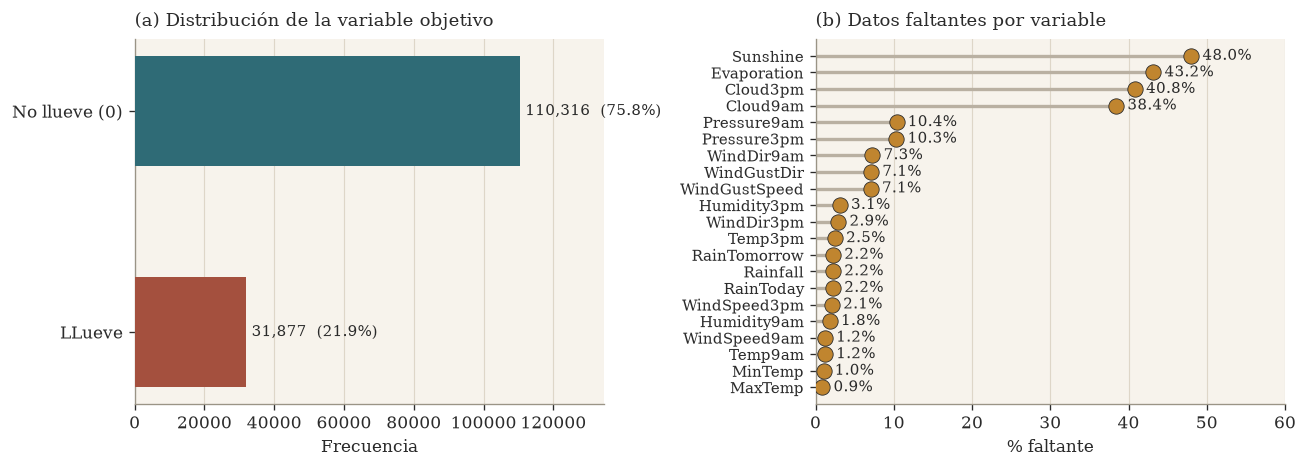

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

vc = df['RainTomorrow'].value_counts().sort_index()
ax[0].barh(['No llueve (0)', 'LLueve'], vc.values, color=[TEAL, BRICK], height=0.5, zorder=3)
for i, v in enumerate(vc.values):
    ax[0].text(v + vc.max()*0.015, i, f'{v:,}  ({v/n*100:.1f}%)', va='center', fontsize=9, color=INK)
ax[0].set_xlim(0, vc.max()*1.22); ax[0].invert_yaxis()
ax[0].set_xlabel('Frecuencia'); ax[0].set_title('(a) Distribución de la variable objetivo')
ax[0].set_axisbelow(True); ax[0].grid(axis='x', color=GRIDC, linewidth=0.7); ax[0].grid(axis='y', visible=False)

miss = (df.isna().mean()*100).sort_values(ascending=False); miss = miss[miss>0]
yy = range(len(miss))
ax[1].hlines(list(yy), 0, miss.values, color=STEM, lw=2.0, zorder=2)
ax[1].scatter(miss.values, list(yy), color=OCHRE, s=85, zorder=3, edgecolor=INK, linewidth=0.5)
for i, v in enumerate(miss.values):
    ax[1].text(v + miss.values.max()*0.03, i, f'{v:.1f}%', va='center', fontsize=9, color=INK)
ax[1].set_yticks(list(yy)); ax[1].set_yticklabels(miss.index, fontsize=9); ax[1].invert_yaxis()
ax[1].set_xlim(0, miss.values.max()*1.25); ax[1].set_xlabel('% faltante')
ax[1].set_title('(b) Datos faltantes por variable')
ax[1].set_axisbelow(True); ax[1].grid(axis='x', color=GRIDC, linewidth=0.7); ax[1].grid(axis='y', visible=False)

plt.tight_layout(); plt.savefig('fig_panorama.png', bbox_inches='tight'); plt.show()

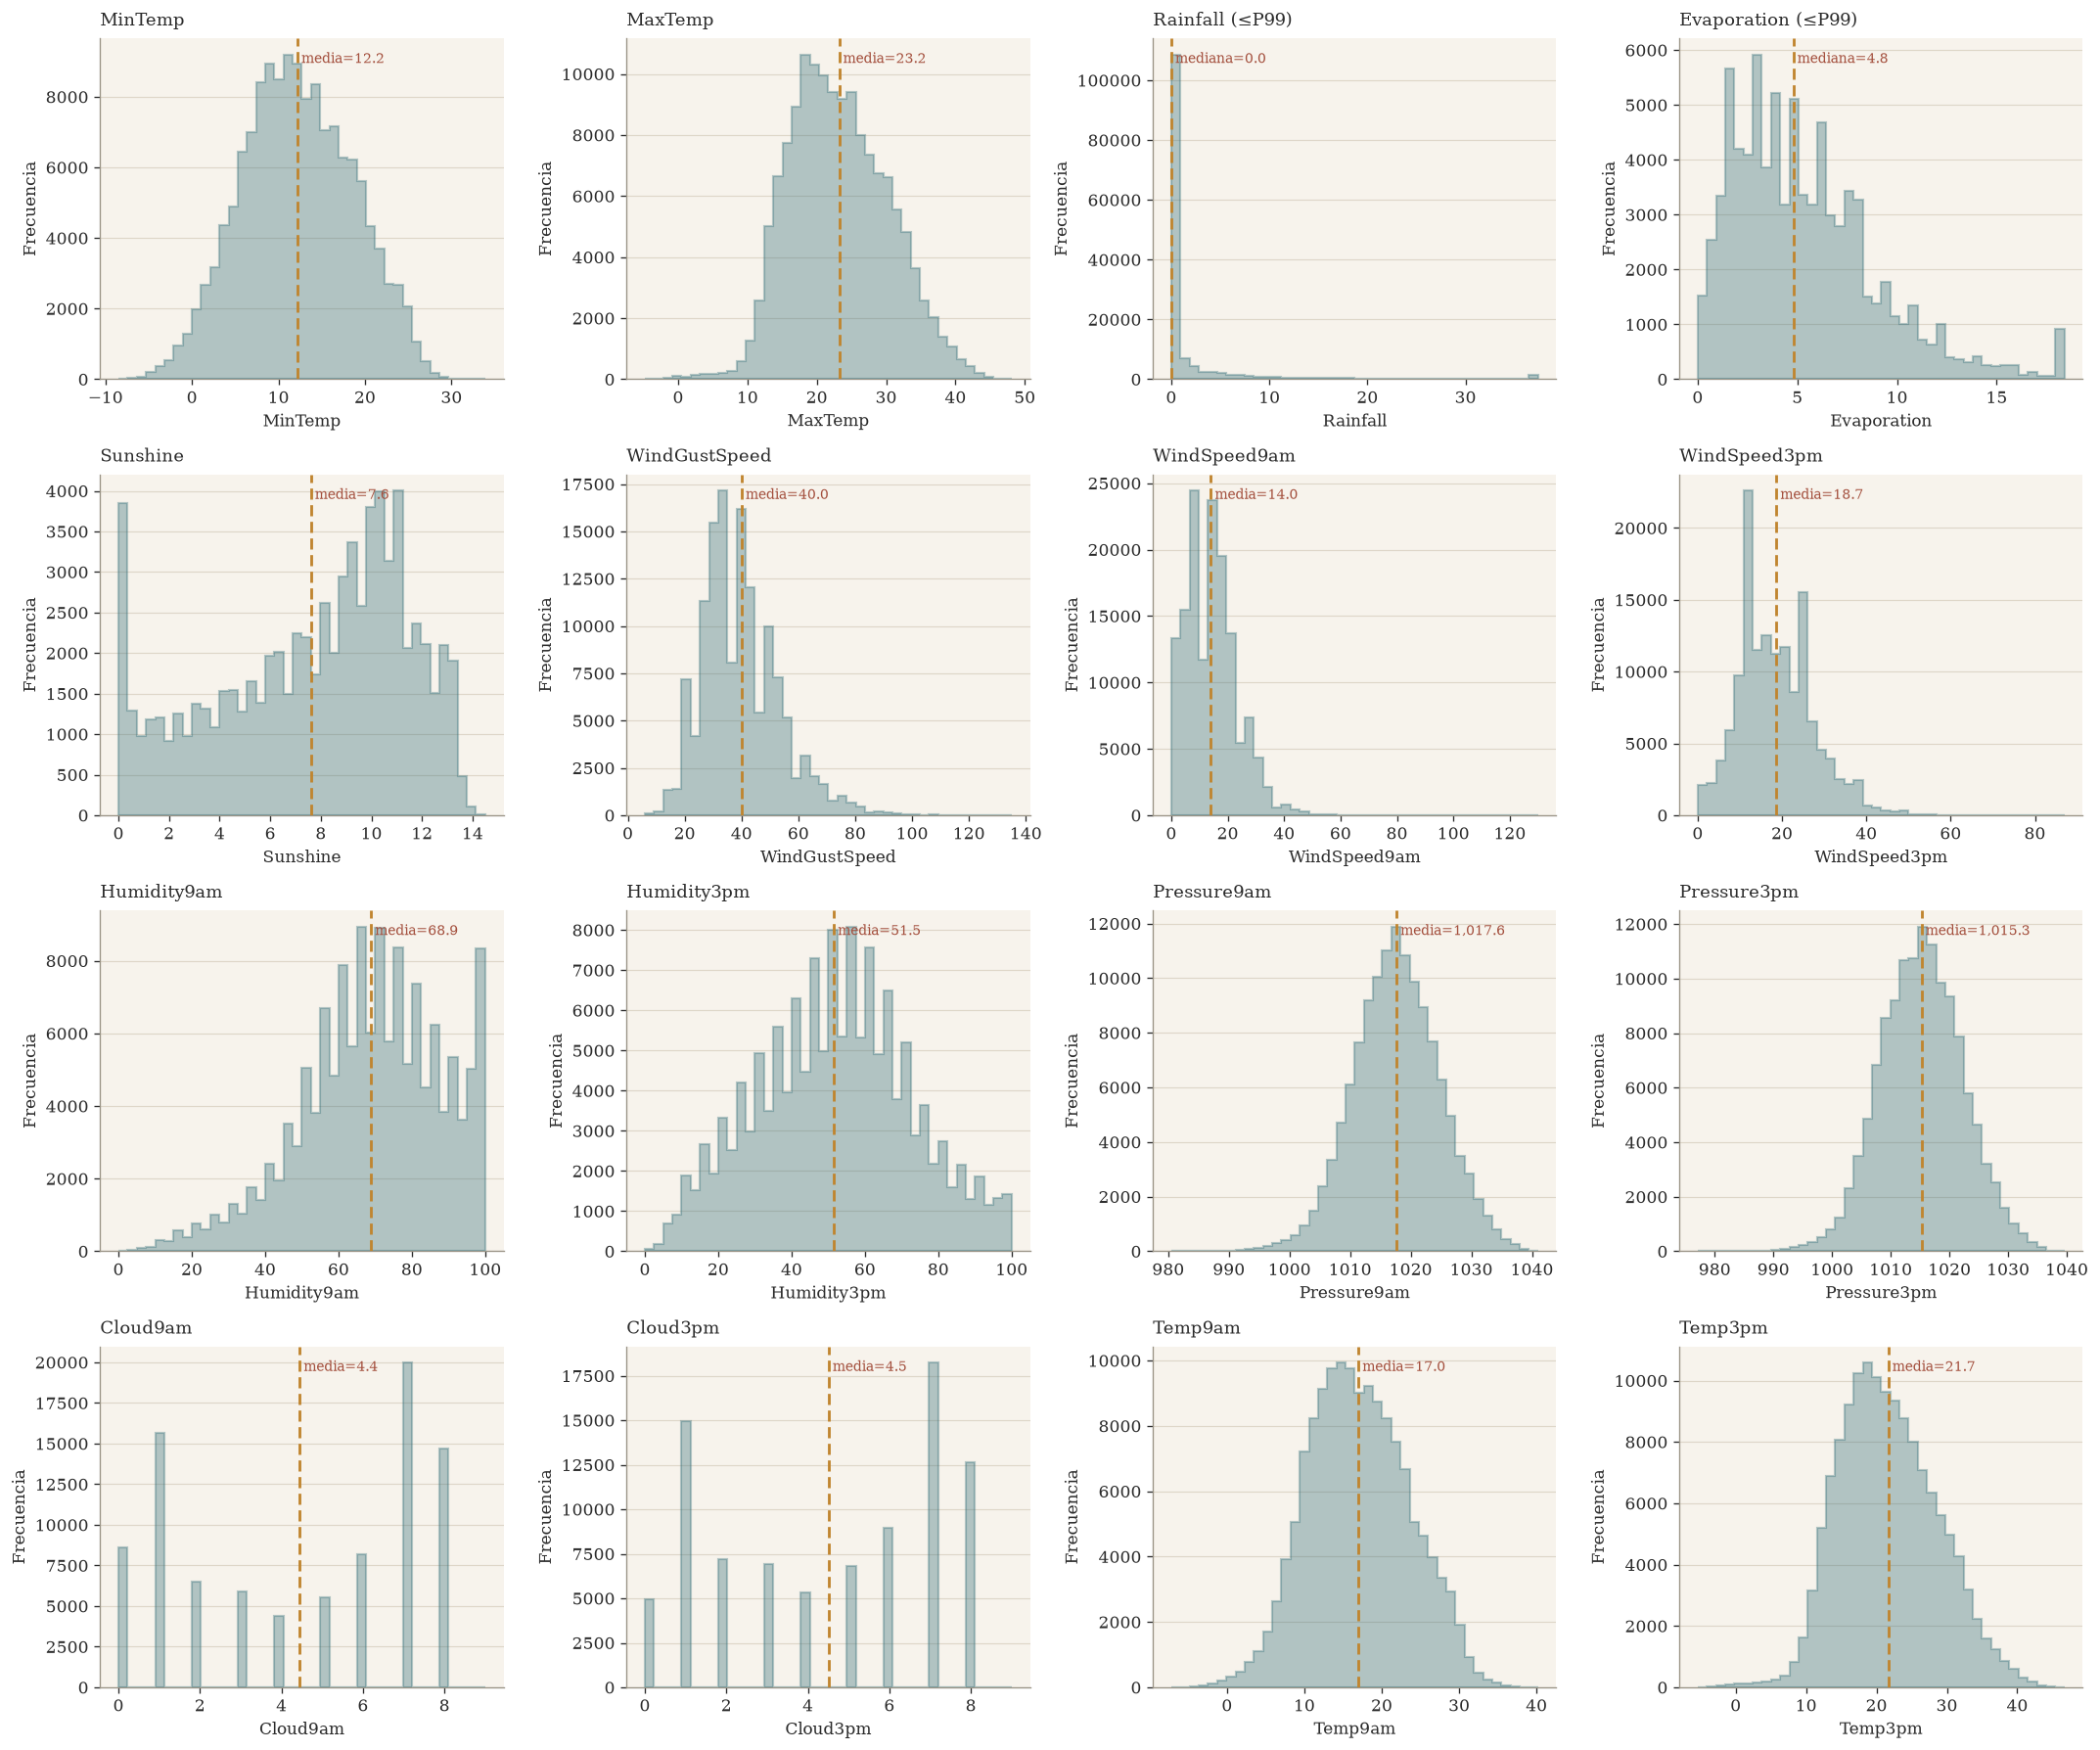

In [6]:
# Figura 2. Distribución de todas las variables numéricas

import numpy as np
import matplotlib.pyplot as plt

# Seleccionar variables numéricas
numericas = df.select_dtypes(include='number').columns

fig, ax = plt.subplots(4, 4, figsize=(18, 15))
ax = ax.flatten()

# Función original del ejemplo
def hist_panel(a, data, titulo, xlab, ref, ref_lab):
    a.hist(data, bins=40, color=TEAL, alpha=0.35,
           edgecolor=TEAL, linewidth=1.3,
           histtype='stepfilled', zorder=3)

    a.axvline(ref, color=OCHRE, ls=(0,(4,2)),
              lw=1.7, zorder=4)

    a.text(ref, a.get_ylim()[1]*0.96,
           f' {ref_lab}={ref:,.1f}',
           color=BRICK, fontsize=8.5, va='top')

    a.set_title(titulo)
    a.set_xlabel(xlab)
    grid_h(a)


# Generar histogramas
for i, c in enumerate(numericas):

    data = df[c].dropna()

    # Variables con asimetría positiva fuerte
    if data.skew() > 1:
        cap = data.quantile(0.99)
        data_grafico = data.clip(upper=cap)
        ref = data.median()
        ref_lab = 'mediana'
        titulo = f'{c} (≤P99)'

    else:
        data_grafico = data
        ref = data.mean()
        ref_lab = 'media'
        titulo = c

    hist_panel(ax[i], data_grafico, titulo,
               c, ref, ref_lab)

    ax[i].set_ylabel('Frecuencia')


plt.tight_layout()
plt.savefig('fig_distribuciones_todas.png',
            dpi=300, bbox_inches='tight')
plt.show()

### 2.4 Figura 3. Matriz de correlaciones

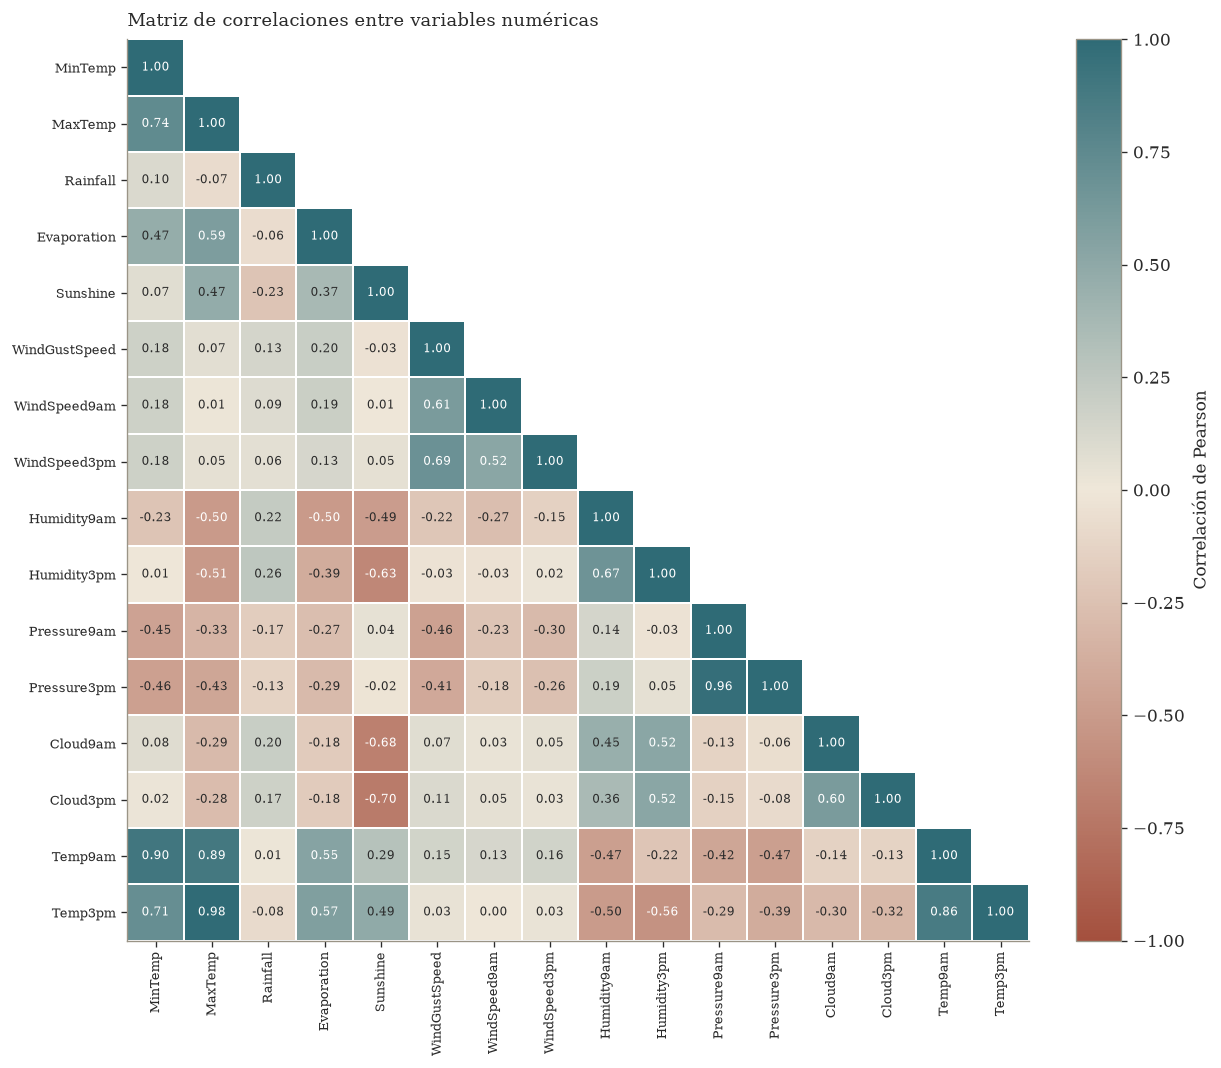

In [7]:
# Figura 3. Matriz de correlaciones entre variables numéricas

# Seleccionar únicamente variables numéricas
corr = df.select_dtypes(include='number').corr()

labels = [c[:22] for c in corr.columns]

M = np.ma.masked_array(
    corr.values,
    mask=np.triu(np.ones_like(corr.values, dtype=bool), k=1)
)

fig, ax = plt.subplots(figsize=(11, 9))
ax.set_facecolor('white')

im = ax.imshow(M, cmap=cmap_corr, vmin=-1, vmax=1)

ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=90, fontsize=8)

ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels, fontsize=8)

for i in range(len(corr)):
    for j in range(len(corr)):
        if j <= i:
            v = corr.values[i, j]
            ax.text(
                j, i, f'{v:.2f}',
                ha='center', va='center',
                fontsize=7,
                color='white' if abs(v) > 0.5 else INK
            )

ax.set_xticks(np.arange(-.5, len(labels), 1), minor=True)
ax.set_yticks(np.arange(-.5, len(labels), 1), minor=True)

ax.grid(which='minor', color='white', linewidth=1.2)
ax.tick_params(which='minor', length=0)

cb = fig.colorbar(im, fraction=0.046, pad=0.04)
cb.set_label('Correlación de Pearson')

ax.set_title('Matriz de correlaciones entre variables numéricas')

plt.tight_layout()
plt.savefig('fig_correlacion_weatherAUS.png',
            dpi=300, bbox_inches='tight')
plt.show()

### 2.5 Análisis bivariado con variables derivadas

El conjunto no trae variables categóricas, así que construimos tres a partir de las numéricas: el tramo
etario, el cuartil de ingreso y un indicador de si el cliente registró algún atraso de 30 a 59 días. Con
ellas revisamos cómo cambia la tasa de morosidad.

In [8]:
# 2.5 Análisis bivariado con variables categóricas

# Crear cuartiles de humedad a las 3 PM
df['cuartil_humedad'] = pd.qcut(
    df['Humidity3pm'],
    4,
    labels=['Q1 (baja)', 'Q2', 'Q3', 'Q4 (alta)']
)
# Convertir la variable objetivo a numérica para calcular proporciones
df['RainTomorrow_bin'] = df['RainTomorrow'].map({
    'No': 0,
    'Yes': 1
})
# Tasa global de lluvia
gm = df['RainTomorrow_bin'].mean() * 100
print(f'Tasa global de lluvia mañana: {gm:.2f}%\n')
# Lluvia según RainToday
print('Probabilidad observada de lluvia según RainToday (%):')
print((df.groupby('RainToday')['RainTomorrow_bin'].mean() * 100).round(2))
# Lluvia según ubicación
print('\nProbabilidad observada de lluvia según Location (%):')
print((df.groupby('Location')['RainTomorrow_bin'].mean() * 100).round(2))
# Lluvia según cuartil de humedad
print('\nProbabilidad observada de lluvia según cuartil de humedad (%):')
print((df.groupby('cuartil_humedad', observed=True)['RainTomorrow_bin'].mean() * 100).round(2))

Tasa global de lluvia mañana: 22.42%

Probabilidad observada de lluvia según RainToday (%):
RainToday
No     15.19
Yes    46.41
Name: RainTomorrow_bin, dtype: float64

Probabilidad observada de lluvia según Location (%):
Location
Adelaide            22.27
Albany              29.91
Albury              20.52
AliceSprings         8.05
BadgerysCreek       19.91
Ballarat            25.79
Bendigo             18.52
Brisbane            22.43
Cairns              31.79
Canberra            18.40
Cobar               12.92
CoffsHarbour        29.43
Dartmoor            31.33
Darwin              26.69
GoldCoast           26.01
Hobart              23.87
Katherine           17.00
Launceston          23.08
Melbourne           26.12
MelbourneAirport    21.70
Mildura             10.87
Moree               13.81
MountGambier        30.36
MountGinini         28.17
Newcastle           24.74
Nhil                15.42
NorahHead           27.59
NorfolkIsland       31.01
Nuriootpa           19.72
PearceRAAF      

### 2.6 Figura 4. LLuvia mañana segun si llueve hoy y segun cuartil de humedad


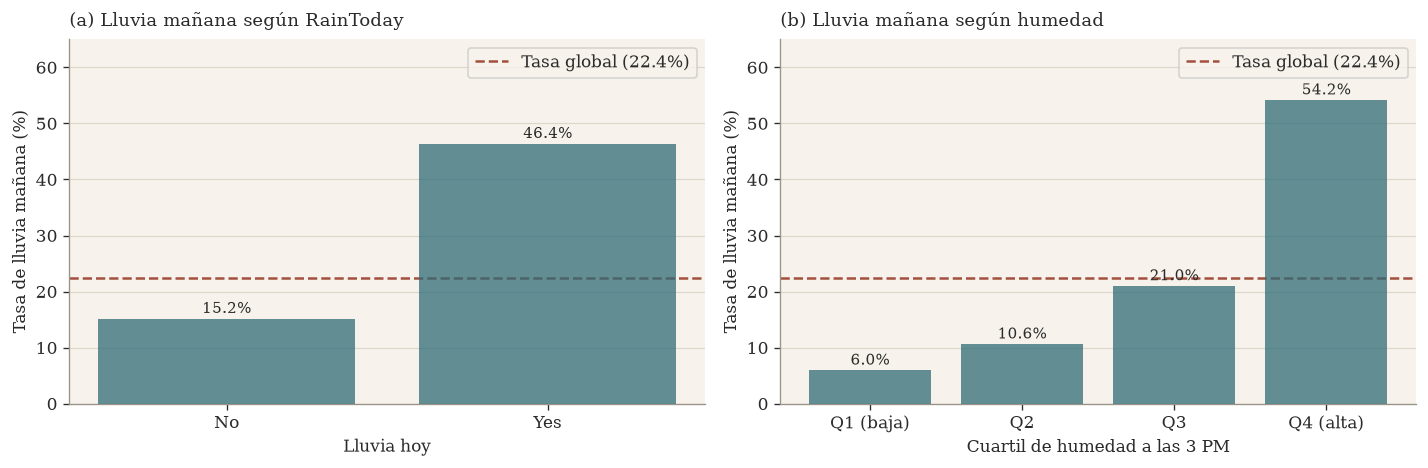

In [9]:
# Figura 4. Tasa de lluvia según variables categóricas

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# (a) Lluvia mañana según RainToday
tasa_rain = df.groupby('RainToday')['RainTomorrow_bin'].mean() * 100

ax[0].bar(
    tasa_rain.index,
    tasa_rain.values,
    color=TEAL,
    alpha=0.75,
    zorder=3
)
ax[0].axhline(gm, color=BRICK, ls='--', lw=1.5,
              label=f'Tasa global ({gm:.1f}%)')

for i, v in enumerate(tasa_rain.values):
    ax[0].text(i, v + 1, f'{v:.1f}%',
               ha='center', fontsize=9, color=INK)

ax[0].set_title('(a) Lluvia mañana según RainToday')
ax[0].set_xlabel('Lluvia hoy')
ax[0].set_ylabel('Tasa de lluvia mañana (%)')
ax[0].set_ylim(0, 65)
ax[0].legend()
grid_h(ax[0])


# (b) Lluvia mañana según cuartil de humedad
tasa_humedad = (
    df.groupby('cuartil_humedad', observed=True)['RainTomorrow_bin']
    .mean() * 100
)

ax[1].bar(
    tasa_humedad.index.astype(str),
    tasa_humedad.values,
    color=TEAL,
    alpha=0.75,
    zorder=3
)

ax[1].axhline(gm, color=BRICK, ls='--', lw=1.5,
              label=f'Tasa global ({gm:.1f}%)')

for i, v in enumerate(tasa_humedad.values):
    ax[1].text(i, v + 1, f'{v:.1f}%',
               ha='center', fontsize=9, color=INK)

ax[1].set_title('(b) Lluvia mañana según humedad')
ax[1].set_xlabel('Cuartil de humedad a las 3 PM')
ax[1].set_ylabel('Tasa de lluvia mañana (%)')
ax[1].set_ylim(0, 65)
ax[1].legend()
grid_h(ax[1])

plt.tight_layout()
plt.savefig('fig_bivariado_weatherAUS.png',
            dpi=300, bbox_inches='tight')
plt.show()

## 3. Estimación de parámetros

Estimación puntual e intervalos de confianza al 95% para tres variables numéricas (edad, ingreso mensual
y número de líneas y préstamos) y para la proporción de morosidad. Tanto para las medias como para la
proporción usamos el intervalo basado en la aproximación normal (método de Wald), que es el procedimiento
visto en clase y que el Teorema Central del Límite justifica dado el gran tamaño muestral.

Nota complementaria (no evaluada): para proporciones extremas o muestras pequeñas, el intervalo de Wilson
mejora la cobertura del de Wald; con el tamaño de muestra de este estudio ambos coinciden. El tema se
desarrolla en el apunte complementario del curso.

In [10]:
z = stats.norm.ppf(0.975)

def ic_media(x):
    x = pd.Series(x).dropna(); m = x.mean(); se = x.std(ddof=1)/np.sqrt(len(x))
    return m, m - z*se, m + z*se, len(x)

def ic_prop(k, n):
    p = k/n; se = np.sqrt(p*(1-p)/n)
    return p, p - z*se, p + z*se

for col, name in [('MaxTemp','temperatura maxima'), ('Humidity3pm', 'humedad 3pm'),
                  ('WindGustSpeed','velocidad de viento')]:
    m, lo, hi, nn = ic_media(df[col])
    print(f'{name:20s}: estimación = {m:>10,.2f}   IC95% [{lo:,.2f}, {hi:,.2f}]   (n = {nn:,})')


temperatura maxima  : estimación =      23.22   IC95% [23.18, 23.26]   (n = 144,199)
humedad 3pm         : estimación =      51.54   IC95% [51.43, 51.65]   (n = 140,953)
velocidad de viento : estimación =      40.04   IC95% [39.96, 40.11]   (n = 135,197)


## 4. Pruebas de hipótesis

### 4.1 Prueba 1. La edad media difiere entre morosos y no morosos (t de Welch)

Formulamos $H_0: \mu_{\text{moroso}} = \mu_{\text{no moroso}}$ contra $H_1: \mu_{\text{moroso}} \neq
\mu_{\text{no moroso}}$, con nivel de significancia 0,05. Revisamos los supuestos: independencia entre
grupos y forma aproximadamente simétrica. Como los grupos tienen tamaños muy dispares y desviaciones
estándar distintas, no asumimos varianzas iguales y usamos la prueba t de Welch, que estima el error
estándar por separado en cada grupo.

Nota complementaria (no evaluada): la igualdad de varianzas puede contrastarse formalmente con la prueba
de Levene, y la elección entre la prueba t estándar y la de Welch admite una discusión más fina. Ambos
temas se desarrollan en el apunte complementario del curso.

In [11]:
# 4.1 Prueba de hipótesis: Humedad3pm según RainTomorrow

from scipy import stats
import numpy as np

# Grupo 1: días en los que llueve mañana
lluvia = df.loc[
    df['RainTomorrow'] == 'Yes',
    'Humidity3pm'
].dropna()

# Grupo 2: días en los que no llueve mañana
sin_lluvia = df.loc[
    df['RainTomorrow'] == 'No',
    'Humidity3pm'
].dropna()

# Estadísticos descriptivos
print("Grupo con lluvia mañana:")
print(f"n = {len(lluvia)}")
print(f"Media = {lluvia.mean():.2f}")
print(f"Desviación estándar = {lluvia.std():.2f}")
print(f"Asimetría = {lluvia.skew():.2f}")

print("\nGrupo sin lluvia mañana:")
print(f"n = {len(sin_lluvia)}")
print(f"Media = {sin_lluvia.mean():.2f}")
print(f"Desviación estándar = {sin_lluvia.std():.2f}")
print(f"Asimetría = {sin_lluvia.skew():.2f}")

# Prueba t de Welch
t, p = stats.ttest_ind(
    lluvia,
    sin_lluvia,
    equal_var=False
)

print("\nResultados de la prueba t de Welch:")
print(f"Estadístico t = {t:.4f}")
print(f"Valor p = {p:.6g}")

# Decisión estadística
alpha = 0.05

if p < alpha:
    print("Se rechaza H0: existen diferencias estadísticamente significativas.")
else:
    print("No se rechaza H0: no hay evidencia suficiente de diferencias.")

Grupo con lluvia mañana:
n = 30913
Media = 68.80
Desviación estándar = 19.04
Asimetría = -0.52

Grupo sin lluvia mañana:
n = 107670
Media = 46.51
Desviación estándar = 18.49
Asimetría = -0.04

Resultados de la prueba t de Welch:
Estadístico t = 182.6077
Valor p = 0
Se rechaza H0: existen diferencias estadísticamente significativas.


### Figura 5. Distribución de humedad segun si llueve o no

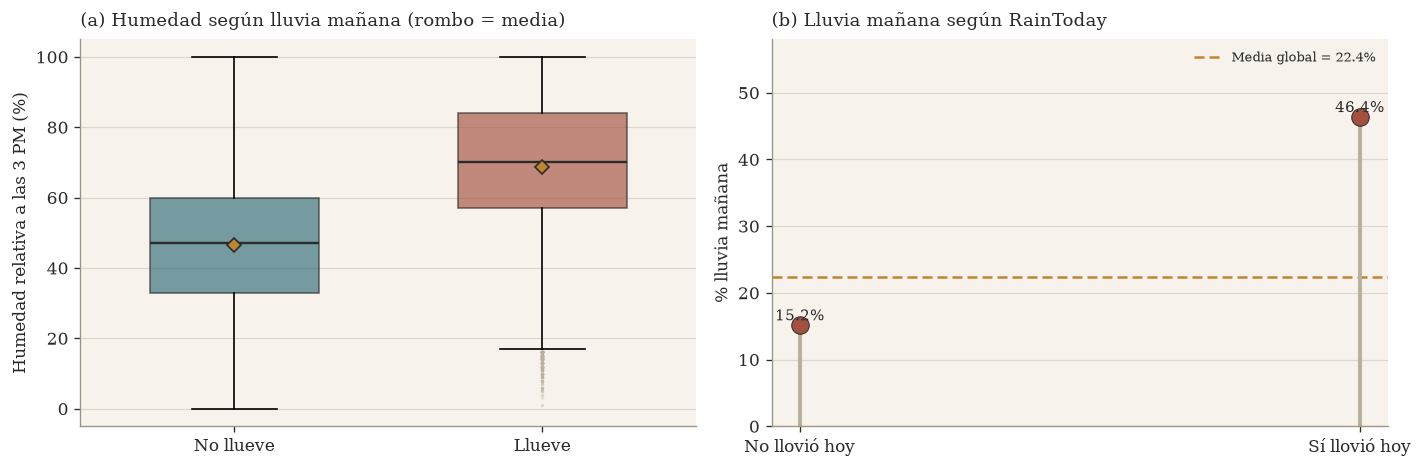

In [12]:
# Figura 5. Visualización de las pruebas de hipótesis

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# (a) Boxplot de Humidity3pm según RainTomorrow

bp = ax[0].boxplot(
    [sin_lluvia, lluvia],
    tick_labels=['No llueve', 'Llueve'],
    patch_artist=True,
    widths=0.55,
    showmeans=True,
    meanprops=dict(marker='D', markerfacecolor=OCHRE,
                   markeredgecolor=INK, markersize=6),
    medianprops=dict(color=INK, linewidth=1.4),
    flierprops=dict(marker='o', markersize=2,
                    markerfacecolor=STEM,
                    markeredgecolor='none', alpha=0.25)
)

for patch, col in zip(bp['boxes'], [TEAL, BRICK]):
    patch.set_facecolor(col)
    patch.set_alpha(0.65)
    patch.set_edgecolor(INK)

ax[0].set_ylabel('Humedad relativa a las 3 PM (%)')
ax[0].set_title('(a) Humedad según lluvia mañana (rombo = media)')
grid_h(ax[0])


# (b) Tasa de lluvia mañana según RainToday (lollipop)

tt = (
    df.dropna(subset=['RainToday'])
    .groupby('RainToday')['RainTomorrow_bin']
    .mean() * 100
)

tt = tt[['No', 'Yes']]

xx = range(len(tt))

# Media global de lluvia mañana
gm = df['RainTomorrow_bin'].mean() * 100

ax[1].axhline(
    gm, color=OCHRE, ls=(0,(4,2)), lw=1.5,
    zorder=2, label=f'Media global = {gm:.1f}%'
)

ax[1].vlines(
    list(xx), 0, tt.values,
    color=STEM, lw=2.4, zorder=2
)

ax[1].scatter(
    list(xx), tt.values,
    color=BRICK, s=110, zorder=3,
    edgecolor=INK, linewidth=0.6
)

for xi, yi in zip(xx, tt.values):
    ax[1].text(
        xi, yi+0.7, f'{yi:.1f}%',
        ha='center', fontsize=9, color=INK
    )

ax[1].set_xticks(list(xx))
ax[1].set_xticklabels(['No llovió hoy', 'Sí llovió hoy'])

ax[1].set_ylabel('% lluvia mañana')
ax[1].set_title('(b) Lluvia mañana según RainToday')

ax[1].set_ylim(0, tt.values.max()*1.25)
grid_h(ax[1])
ax[1].legend(fontsize=8, frameon=False)

plt.tight_layout()
plt.savefig('fig_hipotesis_weatherAUS.png',
            dpi=300, bbox_inches='tight')
plt.show()

### 4.2 Prueba 2. El historial de llueve o no llueve (chi-cuadrado)




In [13]:
tabla = pd.crosstab(df['RainToday'], df['RainTomorrow'])
print(tabla)


RainTomorrow     No    Yes
RainToday                 
No            92728  16604
Yes           16858  14597


In [14]:
# Prueba chi-cuadrado de independencia

chi2, p, gl, esperadas = stats.chi2_contingency(tabla)

print(f"Estadístico chi-cuadrado: {chi2:.4f}")
print(f"Grados de libertad: {gl}")
print(f"Valor p: {p:.6g}")

# Verificación de frecuencias esperadas
print(f"Frecuencia esperada mínima: {esperadas.min():.2f}")

# Decisión estadística
alpha = 0.05

if p < alpha:
    print("Se rechaza H0: existe asociación estadísticamente significativa.")
else:
    print("No se rechaza H0: no existe evidencia suficiente de asociación.")

Estadístico chi-cuadrado: 13799.4796
Grados de libertad: 1
Valor p: 0
Frecuencia esperada mínima: 6971.01
Se rechaza H0: existe asociación estadísticamente significativa.


## Síntesis de resultados

La variable objetivo presenta un desbalance, con un 22,42 % de registros con lluvia al día siguiente. Las medias se estiman mediante intervalos de confianza estrechos debido al tamaño de la muestra. La humedad relativa a las 3 PM difiere significativamente entre días con y sin lluvia posterior, alcanzando promedios de 68,80 % y 46,51 %, respectivamente. La lluvia actual también presenta una asociación significativa con la lluvia del día siguiente (χ² = 13.799,48; p < 0,001), siendo esta aproximadamente tres veces más frecuente cuando ha llovido el día anterior. Además, la probabilidad observada de lluvia aumenta progresivamente según los cuartiles de humedad, desde un 5,96 % hasta un 54,18 %. Estos resultados destacan la relevancia de las condiciones meteorológicas actuales y proporcionan una base estadística para las siguientes fases del proyecto.